# Tennis Match Prediction Model

In [5]:
import numpy as np
import pandas as pd

# Data import
years = [2021, 2022, 2023, 2024, 2025]
dfs = []
for year in years:
    url = f'http://tennis-data.co.uk/{year}/{year}.xlsx'
    #dfs.append(pd.read_excel(url))
    dfs = [pd.read_excel(f"../data/{year}.xlsx") for year in years]
df = pd.concat(dfs).sort_values('Date').reset_index(drop=True)


## Removing Data to Prevent Data Leakage

In [6]:
leakage_columns = ['W1', 'L1', 'W2', 'L2', 'W3', 'L3', 'W4', 'L4', 'W5', 'L5', 'Comment']
df = df.drop(columns=leakage_columns)

df.head()

,ATP,Location,Tournament,Date,Series,Court,Surface,Round,Best of,Winner,...,B365W,B365L,PSW,PSL,MaxW,MaxL,AvgW,AvgL,BFEW,BFEL
0,1,Antalya,Antalya Open,2021-01-07,ATP250,Indoor,Hard,1st Round,3.0,Basilashvili N.,...,1.50,2.50,1.61,2.44,1.67,2.56,1.56,2.42,NaN,NaN
1,1,Antalya,Antalya Open,2021-01-07,ATP250,Indoor,Hard,1st Round,3.0,Celikbilek A.,...,2.50,1.50,2.63,1.54,2.70,1.55,2.57,1.50,NaN,NaN
2,1,Antalya,Antalya Open,2021-01-07,ATP250,Indoor,Hard,1st Round,3.0,Ruusuvuori E.,...,1.50,2.50,1.56,2.58,1.63,3.03,1.52,2.53,NaN,NaN
3,1,Antalya,Antalya Open,2021-01-07,ATP250,Indoor,Hard,1st Round,3.0,Bublik A.,...,1.61,2.20,1.81,2.09,1.87,2.30,1.72,2.11,NaN,NaN
4,1,Antalya,Antalya Open,2021-01-07,ATP250,Indoor,Hard,1st Round,3.0,Goffin D.,...,1.40,2.75,1.46,2.92,1.50,3.00,1.44,2.78,NaN,NaN


## Historical Feature Creation

In [7]:
# General win rate
def compute_winrate(df, window=20):
    # Extract winner and loser columns, rename to 'Player'
    df_w = df[['Date', 'Winner']].rename(columns={'Winner': 'Player'})
    df_w['won'] = 1  # Mark as win
    
    df_l = df[['Date', 'Loser']].rename(columns={'Loser': 'Player'})
    df_l['won'] = 0  # Mark as loss
    
    # Merge both dataframes so each player has one row per match
    df_long = pd.concat([df_w, df_l]).sort_values('Date').reset_index(drop=True)
    
    # Shift values forward to prevent data leakage
    df_long['winrate'] = df_long.groupby('Player')['won'].transform(
        lambda x: x.shift(1).rolling(window, min_periods=3).mean()
        # Last 20 matches, but only if at least 3 exist for that player
    )
    return df_long[['Date', 'Player', 'winrate']]

wr_all = compute_winrate(df)

# Merge win-rate for the winner
df = df.merge(wr_all, left_on=['Date','Winner'],
              right_on=['Date','Player'], how='left')\
       .rename(columns={'winrate': 'Winner_WR'}).drop(columns='Player')

# Merge win-rate for the loser
df = df.merge(wr_all, left_on=['Date','Loser'],
              right_on=['Date','Player'], how='left')\
       .rename(columns={'winrate': 'Loser_WR'}).drop(columns='Player')

# Win rate for different surfaces
def compute_winrate_surface(df, window=20):
    results = []
    # Apply the same logic as above but for each surface
    for surf in df['Surface'].unique():
        df_surf = df[df['Surface'] == surf]
        
        df_w = df_surf[['Date','Winner']].rename(columns={'Winner':'Player'})
        df_w['won'] = 1
        df_l = df_surf[['Date','Loser']].rename(columns={'Loser':'Player'})
        df_l['won'] = 0
        
        df_long = pd.concat([df_w, df_l]).sort_values('Date').reset_index(drop=True)
        df_long['winrate'] = df_long.groupby('Player')['won'].transform(
            lambda x: x.shift(1).rolling(window, min_periods=3).mean()
        )
        df_long['Surface'] = surf
        results.append(df_long[['Date','Player','winrate','Surface']])
    return pd.concat(results)

wr_surf = compute_winrate_surface(df)

df = df.merge(wr_surf, left_on=['Date','Winner','Surface'], right_on=['Date','Player','Surface'], how='left')\
       .rename(columns={'winrate': 'Winner_WR_surf'}).drop(columns='Player')\

df = df.merge(wr_surf, left_on=['Date','Loser','Surface'], right_on=['Date','Player','Surface'], how='left')\
       .rename(columns={'winrate': 'Loser_WR_surf'}).drop(columns='Player')\


# Head-to-head record
def compute_h2h(df):
    h2h = []
    # Sort chronologically to look only at historical matches
    df_sorted = df.sort_values('Date').reset_index(drop=True)
    for _, row in df_sorted.iterrows():
        p1, p2, date = row['Winner'], row['Loser'], row['Date']
        past = df_sorted[df_sorted['Date'] < date]
        wins_p1 = ((past['Winner']==p1) & (past['Loser']==p2)).sum()
        wins_p2 = ((past['Winner']==p2) & (past['Loser']==p1)).sum()
        total = wins_p1 + wins_p2
        h2h.append(wins_p1 / total if total > 0 else 0.5)
    return h2h

df['H2H_winner'] = compute_h2h(df)

print(df['Winner_WR'].describe())
print(df['Loser_WR'].describe())

count    24500.00000
mean         0.57705
std          0.15844
min          0.00000
25%          0.50000
50%          0.55000
75%          0.70000
max          1.00000
Name: Winner_WR, dtype: float64
count    23935.000000
mean         0.523909
std          0.150358
min          0.000000
25%          0.450000
50%          0.500000
75%          0.650000
max          1.000000
Name: Loser_WR, dtype: float64


## Renaming Columns and Splitting Dataset into 2 Parts

In [8]:
df_half1 = df.sample(frac=0.5, random_state=42).copy()
df_half2 = df.drop(df_half1.index).copy()

#First half
df_half1['P1'] = df_half1['Winner']
df_half1['P2'] = df_half1['Loser']

df_half1['R1'] = df_half1['WRank']
df_half1['R2'] = df_half1['LRank']

df_half1['Points1'] = df_half1['WPts']
df_half1['Points2'] = df_half1['LPts']

df_half1['P1365'] = df_half1['B365W']
df_half1['P2365']  = df_half1['B365L']
df_half1['P1PS'] = df_half1['PSW']
df_half1['P2PS'] = df_half1['PSL']

df_half1['P1Max'] = df_half1['MaxW']
df_half1['P2Max'] = df_half1['MaxL']
df_half1['P1Avg'] = df_half1['AvgW']
df_half1['P2Avg'] = df_half1['AvgL']
df_half1['P1BFE'] = df_half1['BFEW']
df_half1['P2BFE'] = df_half1['BFEL']

df_half1['P1_WR']      = df_half1['Winner_WR']
df_half1['P2_WR']      = df_half1['Loser_WR']
df_half1['P1_WR_surf'] = df_half1['Winner_WR_surf']
df_half1['P2_WR_surf'] = df_half1['Loser_WR_surf']
df_half1['H2H']        = df_half1['H2H_winner']

df_half1['Target'] = 1

#Second half: swap players to create the negative class
df_half2['P1'] = df_half2['Loser']
df_half2['P2'] = df_half2['Winner']

df_half2['R1'] = df_half2['LRank']
df_half2['R2'] = df_half2['WRank']

df_half2['Points1'] = df_half2['LPts']
df_half2['Points2'] = df_half2['WPts']

df_half2['P1365'] = df_half2['B365L']
df_half2['P2365'] = df_half2['B365W']
df_half2['P1PS'] = df_half2['PSL']
df_half2['P2PS'] = df_half2['PSW']

df_half2['P1Max'] = df_half2['MaxL']
df_half2['P2Max'] = df_half2['MaxW']
df_half2['P1Avg'] = df_half2['AvgL']
df_half2['P2Avg'] = df_half2['AvgW']
df_half2['P1BFE'] = df_half2['BFEL']
df_half2['P2BFE'] = df_half2['BFEW']

df_half2['P1_WR']      = df_half2['Loser_WR']
df_half2['P2_WR']      = df_half2['Winner_WR']
df_half2['P1_WR_surf'] = df_half2['Loser_WR_surf']
df_half2['P2_WR_surf'] = df_half2['Winner_WR_surf']
df_half2['H2H']        = 1 - df_half2['H2H_winner']


df_half2['Target'] = 0

#Reassemble the dataset
df_final = pd.concat([df_half1, df_half2])

df_final = df_final.drop(columns=['Winner', 'Loser', 'WRank', 'LRank', 'WPts', 'LPts', 'B365W', 'B365L', 'PSW', 'PSL', 'MaxW', 'MaxL', 'AvgW', 'AvgL', 'BFEW', 'BFEL', 'Wsets', 'Lsets', 'Winner_WR','Loser_WR', 'Winner_WR_surf','Loser_WR_surf', 'H2H_winner'])

df_final.head()


,ATP,Location,Tournament,Date,Series,Court,Surface,Round,Best of,P1,...,P1Avg,P2Avg,P1BFE,P2BFE,P1_WR,P2_WR,P1_WR_surf,P2_WR_surf,H2H,Target
10296,51,Winston-Salem,Winston-Salem Open at Wake Forest University,2022-08-24,ATP250,Outdoor,Hard,3rd Round,3.0,Van De Zandschulp B.,...,1.53,2.47,NaN,NaN,0.550000,0.450000,0.550000,0.400000,0.500000,1
24565,42,Washington,Citi Open,2025-07-27,ATP500,Outdoor,Hard,The Final,3.0,De Minaur A.,...,1.42,2.80,NaN,NaN,0.650000,0.550000,0.750000,0.600000,0.333333,1
8193,28,Madrid,Mutua Madrid Open,2022-05-03,Masters 1000,Outdoor,Clay,1st Round,3.0,Van De Zandschulp B.,...,3.05,1.37,NaN,NaN,0.600000,0.600000,0.636364,0.700000,1.000000,1
15350,42,Atlanta,Atlanta Open,2023-07-28,ATP250,Outdoor,Hard,2nd Round,3.0,Nishikori K.,...,1.52,2.51,NaN,NaN,0.650000,0.250000,0.500000,0.285714,0.500000,1
3096,36,London,Wimbledon,2021-07-01,Grand Slam,Outdoor,Grass,2nd Round,5.0,Duckworth J.,...,3.83,1.26,NaN,NaN,0.533333,0.526316,0.500000,0.727273,0.500000,1


## Missing Data Analysis

In [9]:
from data_utils import check_missing_data
stats = check_missing_data(df_final)
print(stats)

            Missing valurd  % of total
P2BFE                24882   97.108067
P1BFE                24882   97.108067
P2_WR_surf            1882    7.344964
P1_WR_surf            1859    7.255200
P2_WR                 1406    5.487258
P1_WR                 1405    5.483355
P1365                  198    0.772743
P2365                  198    0.772743
P2PS                   171    0.667369
P1PS                   171    0.667369
R1                      19    0.074152
Points1                 19    0.074152
R2                      18    0.070249
Points2                 18    0.070249
P1Avg                   15    0.058541
P2Avg                   15    0.058541
P2Max                   15    0.058541
Best of                 15    0.058541
P1Max                   15    0.058541
H2H                      0    0.000000
ATP                      0    0.000000
Location                 0    0.000000
P2                       0    0.000000
P1                       0    0.000000
Round                    

## Managing Missing Betting Data

In [10]:
# Remove the most sparse columns
df_final.drop(columns = ['P1BFE', 'P2BFE'], inplace = True, errors = 'ignore')

# Define which columns to fill
p1_cols = ['P1PS', 'P1365']
p2_cols = ['P2PS', 'P2365']

# Fill player 1's columns with mean values
for col in p1_cols:
    mean_value = df_final['P1Avg'].mean()
    df_final[col] = df_final[col].fillna(mean_value)

# Fill player 2's columns with mean values
for col in p2_cols:
    mean_value = df_final['P2Avg'].mean()
    df_final[col] = df_final[col].fillna(mean_value)


## Checking Results

In [11]:
stats = check_missing_data(df_final)
print(stats)

            Missing valurd  % of total
P2_WR_surf            1882    7.344964
P1_WR_surf            1859    7.255200
P2_WR                 1406    5.487258
P1_WR                 1405    5.483355
R1                      19    0.074152
Points1                 19    0.074152
Points2                 18    0.070249
R2                      18    0.070249
P2Avg                   15    0.058541
Best of                 15    0.058541
P1Avg                   15    0.058541
P2Max                   15    0.058541
P1Max                   15    0.058541
P1PS                     0    0.000000
H2H                      0    0.000000
P2PS                     0    0.000000
ATP                      0    0.000000
P2365                    0    0.000000
P1365                    0    0.000000
Location                 0    0.000000
P2                       0    0.000000
P1                       0    0.000000
Round                    0    0.000000
Surface                  0    0.000000
Court                    

## Removing Rows with Missing Critical Values

In [12]:
df_final.dropna(inplace=True)
stats = check_missing_data(df_final)
print(stats)

            Missing valurd  % of total
ATP                      0         0.0
P1365                    0         0.0
H2H                      0         0.0
P2_WR_surf               0         0.0
P1_WR_surf               0         0.0
P2_WR                    0         0.0
P1_WR                    0         0.0
P2Avg                    0         0.0
P1Avg                    0         0.0
P2Max                    0         0.0
P1Max                    0         0.0
P2PS                     0         0.0
P1PS                     0         0.0
P2365                    0         0.0
Points2                  0         0.0
Location                 0         0.0
Points1                  0         0.0
R2                       0         0.0
R1                       0         0.0
P2                       0         0.0
P1                       0         0.0
Best of                  0         0.0
Round                    0         0.0
Surface                  0         0.0
Court                    

## Creating New Features and Analyzing Them

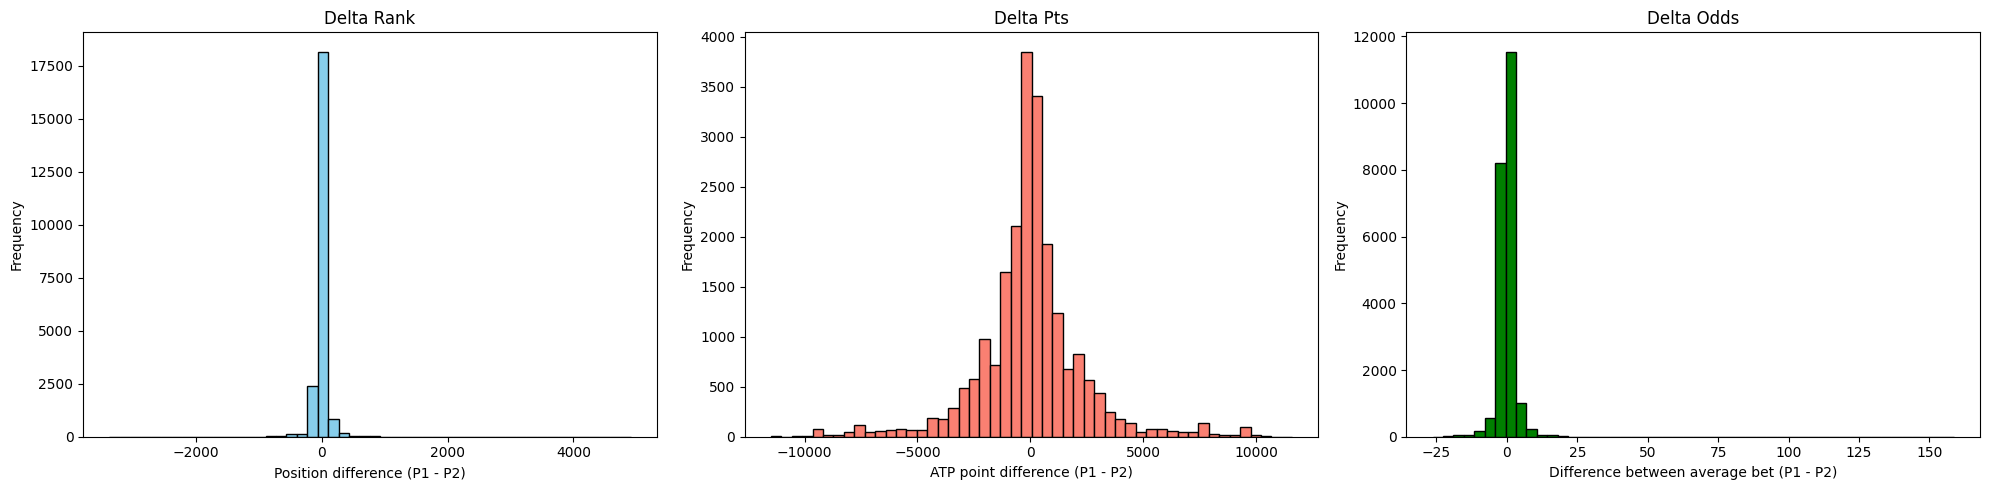

In [13]:

import matplotlib.pyplot as plt

df_final['delta_rank'] = df_final['R1'] - df_final['R2']
df_final['ATP_points'] = df_final['Points1'] - df_final['Points2']

df_final['delta_odds'] = df_final['P1Avg'] - df_final['P2Avg']


# Create three graphs: ranking, points, and odds
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))

# Delta Rank
ax1.hist(df_final['delta_rank'], bins=50, color='skyblue', edgecolor='black')
ax1.set_title('Delta Rank')
ax1.set_xlabel('Position difference (P1 - P2)')
ax1.set_ylabel('Frequency')

# Delta Pts
ax2.hist(df_final['ATP_points'], bins=50, color='salmon', edgecolor='black')
ax2.set_title('Delta Pts')
ax2.set_xlabel('ATP point difference (P1 - P2)')
ax2.set_ylabel('Frequency')

# Delta Odds
ax3.hist(df_final['delta_odds'], bins=50, color='green', edgecolor='black')
ax3.set_title('Delta Odds')
ax3.set_xlabel('Difference between average bet (P1 - P2)')
ax3.set_ylabel('Frequency')

# Delta Win Rate
df_final['delta_WR'] = df_final['P1_WR'] - df_final['P2_WR']
df_final['delta_WR_surf'] = df_final['P1_WR_surf'] - df_final['P2_WR_surf']

df_final.drop(columns=['P1Max', 'P1365', 'P1PS', 'P2Max', 'P2365', 'P2PS'], inplace=True)

plt.tight_layout()
plt.show()

## Converting Date Format and Reordering Data Chronologically

In [14]:
df_final['Date'] = pd.to_datetime(df_final['Date'])

df_final = df_final.sort_values(by = 'Date')
df_final = df_final.reset_index(drop = True)

## Manual Encoding (Round and Court)

In [15]:
# Map tournament rounds to numeric values
round_map = {'1st Round': 1, '2nd Round': 2, '3rd Round': 3, '4th Round': 4, 'Quarterfinals': 5, 'Semifinals': 6, 'The Final': 7, 'Round Robin': 0}

# Apply mapping to round column
df_final['Round'] = df_final['Round'].map(round_map)

# Convert court type to binary (0 = Outdoor, 1 = Indoor)
df_final['Court'] = df_final['Court'].map({'Outdoor': 0, 'Indoor': 1})



## One-Hot Encoding (Surface and Series)

In [16]:
# Use one-hot encoding for categorical features without hierarchy
df_final = pd.get_dummies(df_final, columns = ['Surface', 'Series'], prefix = ['Surf', 'Ser'])

## Removing Player Names and Dates

In [17]:
cols_to_drop = ['P1', 'P2', 'Tournament', 'Location', 'Date', 'ATP']
df_final.drop(columns = cols_to_drop, inplace = True, errors = 'ignore')

## Splitting Dataset and Training Random Forest Model

Training samples: 17592, Test samples: 4398


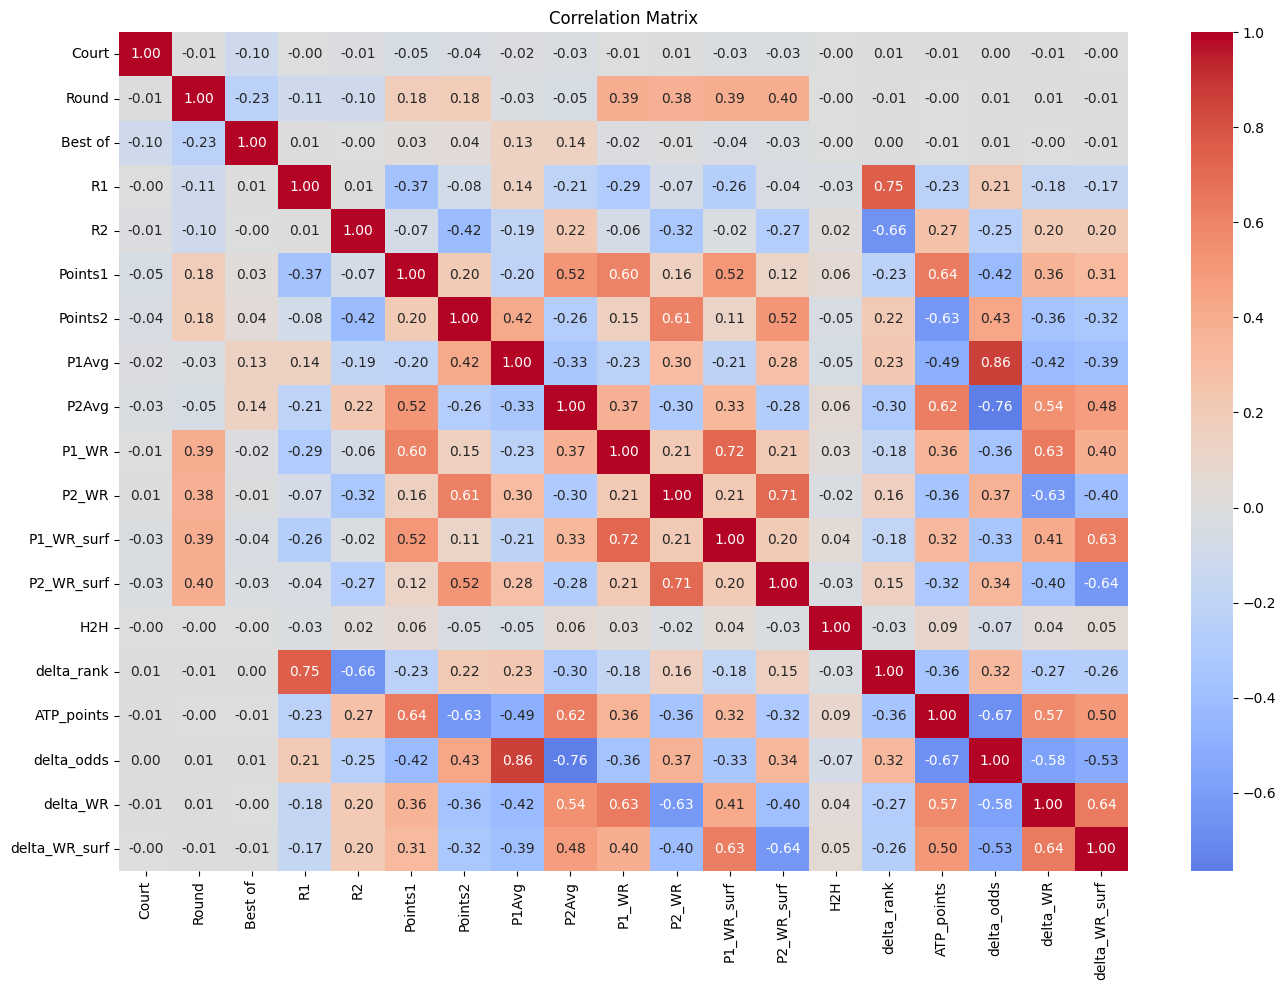


RFECV selected 16 features
['Round', 'R1', 'R2', 'Points1', 'Points2', 'P1Avg', 'P2Avg', 'P1_WR', 'P2_WR', 'P1_WR_surf', 'P2_WR_surf', 'delta_rank', 'ATP_points', 'delta_odds', 'delta_WR', 'delta_WR_surf']
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best parameters: {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 10, 'n_estimators': 100}
Accuracy: 67.76%

Classification report:
               precision    recall  f1-score   support

           0       0.68      0.68      0.68      2195
           1       0.68      0.68      0.68      2203

    accuracy                           0.68      4398
   macro avg       0.68      0.68      0.68      4398
weighted avg       0.68      0.68      0.68      4398



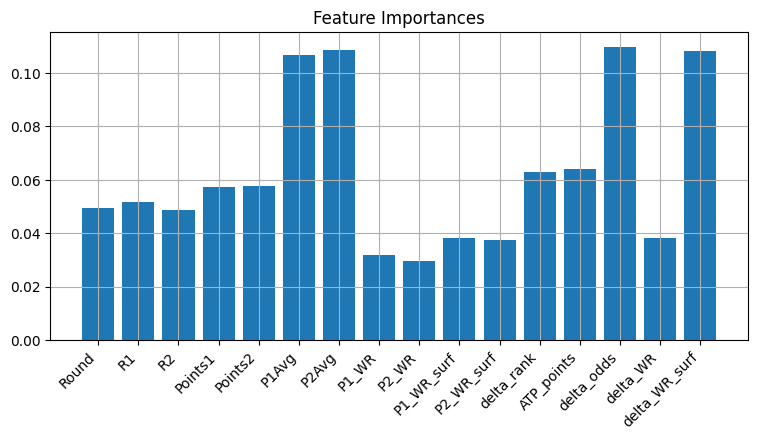

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_selection import RFECV
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit

# TimeSeriesSplit ensures that each cross-validation fold respects 
# chronological order: the model is always trained on past data 
# and validated on future data, preventing future leakage
tscv = TimeSeriesSplit(n_splits=3)

# Use the dataframe as it is already ordered chronologically

df_final_sorted = df_final.reset_index(drop=True)

# Re-extract target and numeric features after sorting
y = df_final_sorted['Target']
x_sorted = df_final_sorted.drop(columns=['Target'], errors='ignore')
x_sorted = x_sorted.select_dtypes(include=[np.number])

# Split dataset chronologically (80% train, 20% test)
split_index = int(len(df_final_sorted) * 0.8)
x_train, x_test = x_sorted.iloc[:split_index], x_sorted.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# Scale only the columns that exist
scaler = StandardScaler()
cols_to_scale = ['delta_rank', 'ATP_points', 'delta_odds',
                 'P1Avg', 'P2Avg', 'R1', 'R2', 'Points1', 'Points2',
                 'P1_WR', 'P2_WR', 'P1_WR_surf', 'P2_WR_surf', 'H2H',
                 'delta_WR', 'delta_WR_surf']
cols_to_scale = [c for c in cols_to_scale if c in x_train.columns]

x_train = x_train.copy()
x_test  = x_test.copy()

# fit_transform on train: learns mean and std exclusively from training data
# transform only on test: applies the same parameters learned from train
# to avoid contaminating the test set with information from its own distribution
if cols_to_scale:
    x_train[cols_to_scale] = scaler.fit_transform(x_train[cols_to_scale])
    x_test[cols_to_scale]  = scaler.transform(x_test[cols_to_scale])

print(f"Training samples: {len(x_train)}, Test samples: {len(x_test)}")

# Correlation matrix
corr = x_train.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

# Use RFECV to select best features
selector = RFECV(
    estimator=RandomForestClassifier(n_estimators=100, random_state=42),
    step=3,  # Remove features in steps
    cv=tscv,  # TimeSeriesSplit
    scoring='accuracy',
    n_jobs=-1
)
selector.fit(x_train, y_train)

# Transform data with selected features
x_train_selected = selector.transform(x_train)
x_test_selected = selector.transform(x_test)
features_rimaste = x_sorted.columns[selector.support_]

print(f"\nRFECV selected {selector.n_features_} features")
print(list(features_rimaste))

# Hyperparameter tuning for Random Forest
param_grid = {
    'n_estimators': [100, 200],   # number of trees in the forest
    'max_depth': [8, 12, None],   # None = trees grow until pure leaves
    'min_samples_leaf': [5, 10],  # higher values prevent overfitting
    'criterion': ['gini']         # measures split quality (impurity)
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    n_jobs=-1,  # use all available CPU cores
    verbose=1   # print progress during search
)
grid_search.fit(x_train_selected, y_train)

# Evaluate best model
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(x_test_selected)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print("\nClassification report:\n", classification_report(y_test, y_pred))

# Feature importance
importances = best_rf.feature_importances_

selected_feature_names = list(features_rimaste)
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(range(len(importances)), importances)
ax.set_title("Feature Importances")
ax.set_xticks(range(len(importances)))
ax.set_xticklabels(selected_feature_names, rotation=45, ha='right')
ax.grid()

## LightGBM Model

In [19]:
!pip3 install lightgbm


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip


In [20]:
import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import TimeSeriesSplit

# Create time-based cross-validation splits
tscv = TimeSeriesSplit(n_splits=3)

lgb_model = lgb.LGBMClassifier(
    objective='binary', # Binary classification task
    random_state=42, # Reproducibility
    verbose=-1  # Suppress training logs
)

param_dist = {
    'n_estimators':  [100, 200],
    'learning_rate': [0.05, 0.1],
    'num_leaves':    [31, 63],
    'max_depth':     [4, 6],
}


search = RandomizedSearchCV(
    estimator=lgb_model,  # Model to optimize
    param_distributions=param_dist, # Parameter search space
    n_iter=10,  # Test 10 random combinations
    cv=tscv, # Time-series cross-validation
    scoring='accuracy',  # Evaluation metric
    n_jobs=-1, # Use all CPU cores
    random_state=42, # Reproducibility
    verbose=1 # Show search progress
)

# Train the model on selected features
search.fit(x_train_selected, y_train)

# Best model found
best_lgb = search.best_estimator_

# Predict on the test set
y_pred_lgb = best_lgb.predict(x_test_selected)

print(f"Best parameters: {search.best_params_}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lgb):.2%}")
print("\nClassification report:\n", classification_report(y_test, y_pred_lgb))

Fitting 3 folds for each of 10 candidates, totalling 30 fits


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/

Best parameters: {'num_leaves': 31, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.1}
Accuracy: 68.44%

Classification report:
               precision    recall  f1-score   support

           0       0.69      0.67      0.68      2195
           1       0.68      0.70      0.69      2203

    accuracy                           0.68      4398
   macro avg       0.68      0.68      0.68      4398
weighted avg       0.68      0.68      0.68      4398



/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


=== MODEL COMPARISON ===
Random Forest:  67.76%
LightGBM:       68.44%


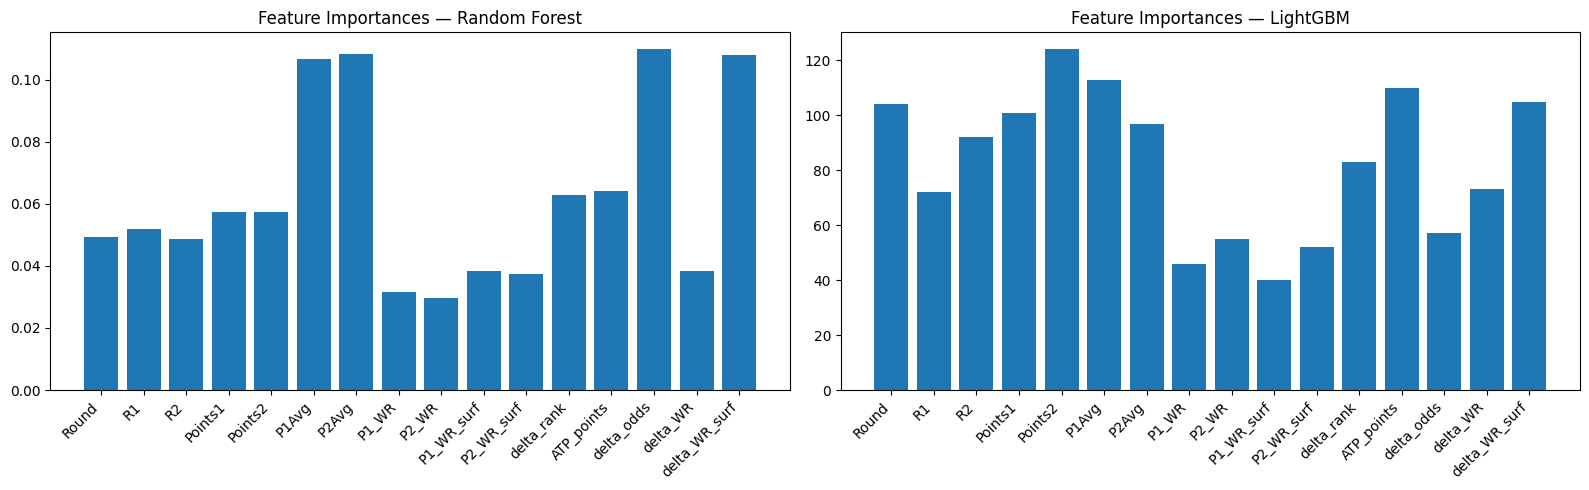

In [21]:
print("=== MODEL COMPARISON ===")
print(f"Random Forest:  {accuracy_score(y_test, y_pred):.2%}")
print(f"LightGBM:       {accuracy_score(y_test, y_pred_lgb):.2%}")

# Feature importance comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# RF importance (already generated)
ax1.bar(range(len(importances)), importances)
ax1.set_title("Feature Importances — Random Forest")
ax1.set_xticks(range(len(importances)))
ax1.set_xticklabels(selected_feature_names, rotation=45, ha='right')

# LightGBM importance
lgb_importances = best_lgb.feature_importances_
ax2.bar(range(len(lgb_importances)), lgb_importances)
ax2.set_title("Feature Importances — LightGBM")
ax2.set_xticks(range(len(lgb_importances)))
ax2.set_xticklabels(selected_feature_names, rotation=45, ha='right')

plt.tight_layout()
plt.show()

## Error Analysis

=== LightGBM: Average features for correct/incorrect predictions ===
             delta_odds  delta_rank  delta_WR       H2H
correct_lgb                                            
False          0.002373    0.024241  0.019762 -0.020989
True          -0.048258   -0.027364  0.034299  0.050706


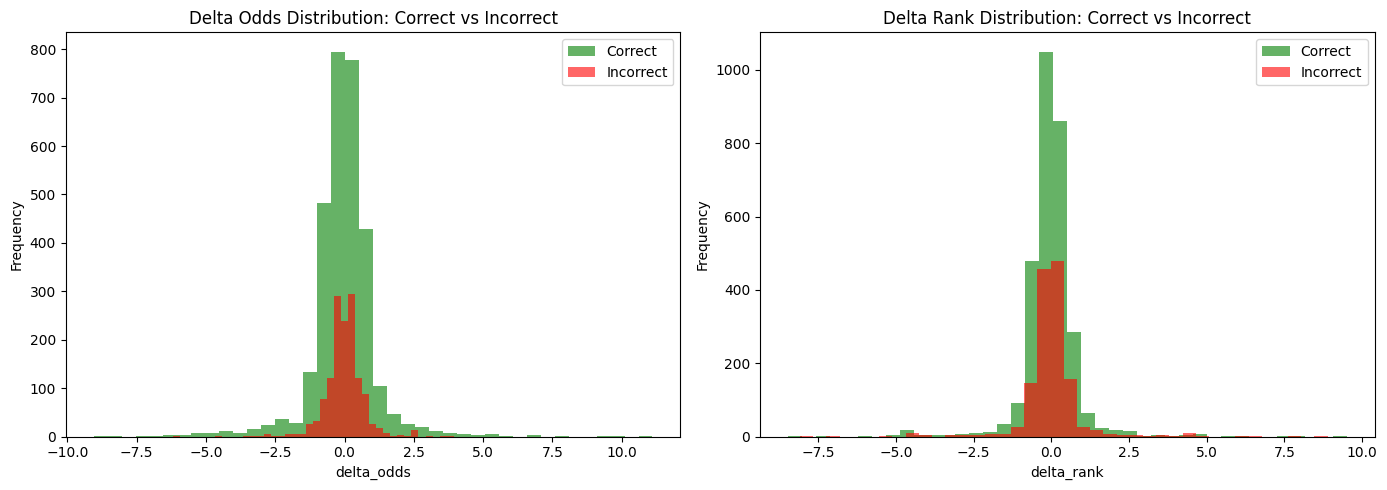


=== Accuracy by Tournament Round ===
Round
0    0.666667
1    0.617091
2    0.677543
3    0.750980
4    0.769231
5    0.694864
6    0.682373
7    0.838346
Name: correct_lgb, dtype: float64


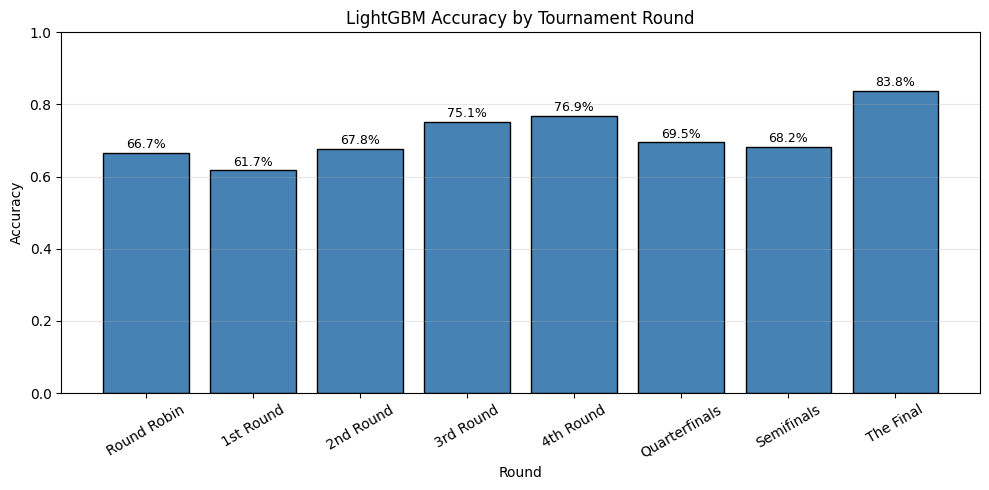


=== Top 10 Most Confident Errors ===
       delta_odds  delta_rank  delta_WR       H2H  y_true
19698    3.935470    0.442724 -1.569764  1.896534       1
20238    3.671308    1.575097 -1.569764  1.896534       1
18747    3.046925    2.496796 -1.833663  1.896534       1
17770    2.642106    0.363722 -1.833663  1.896534       1
17771    2.642106    0.363722 -1.833663  1.896534       1
17776    2.642106    0.363722 -1.833663  1.896534       1
17785    2.642106    0.363722 -1.833663  1.896534       1
17791    2.642106    0.363722 -1.833663  1.896534       1
17793    2.642106    0.363722 -1.833663  1.896534       1
17794    2.642106    0.363722 -1.833663  1.896534       1


In [22]:
# ============================================
# ERROR ANALYSIS
# ============================================

# Analyze where models make incorrect predictions
# Add predictions and correctness indicators to test set
# Compare feature distributions between correct and incorrect predictions
# Identify patterns in model failures

results = x_test.copy()  # Copy test set

# Add predictions and true labels
results['y_true']     = y_test.values
results['y_pred_rf']  = y_pred
results['y_pred_lgb'] = y_pred_lgb

# Check correctness of predictions
results['correct_rf']  = results['y_true'] == results['y_pred_rf']
results['correct_lgb'] = results['y_true'] == results['y_pred_lgb']

# Compare feature averages: correct vs incorrect predictions
print("=== LightGBM: Average features for correct/incorrect predictions ===")
print(results.groupby('correct_lgb')[['delta_odds', 'delta_rank', 
                                       'delta_WR', 'H2H']].mean())

# Error distribution analysis for delta_odds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Divide test set into two groups based on prediction correctness
# to compare feature distributions between correct and incorrect predictions
correct   = results[results['correct_lgb'] == True]['delta_odds']
incorrect = results[results['correct_lgb'] == False]['delta_odds']

axes[0].hist(correct,   bins=40, alpha=0.6, color='green', label='Correct')
axes[0].hist(incorrect, bins=40, alpha=0.6, color='red',   label='Incorrect')
axes[0].set_title('Delta Odds Distribution: Correct vs Incorrect')
axes[0].set_xlabel('delta_odds')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Error distribution analysis for delta_rank
correct_r   = results[results['correct_lgb'] == True]['delta_rank']
incorrect_r = results[results['correct_lgb'] == False]['delta_rank']

axes[1].hist(correct_r,   bins=40, alpha=0.6, color='green', label='Correct')
axes[1].hist(incorrect_r, bins=40, alpha=0.6, color='red',   label='Incorrect')
axes[1].set_title('Delta Rank Distribution: Correct vs Incorrect')
axes[1].set_xlabel('delta_rank')
axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.tight_layout()
plt.show()

# Accuracy by tournament round
print("\n=== Accuracy by Tournament Round ===")
print(results.groupby('Round')['correct_lgb'].mean().sort_index())

import matplotlib.pyplot as plt

# Accuracy per round
round_accuracy = results.groupby('Round')['correct_lgb'].mean().sort_index()

# Mapping per le etichette
round_labels = {
    0: 'Round Robin',
    1: '1st Round',
    2: '2nd Round', 
    3: '3rd Round',
    4: '4th Round',
    5: 'Quarterfinals',
    6: 'Semifinals',
    7: 'The Final'
}

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(
    [round_labels[r] for r in round_accuracy.index],
    round_accuracy.values,
    color='steelblue',
    edgecolor='black'
)

# Adding the value above each bar
for bar, val in zip(bars, round_accuracy.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f'{val:.1%}',
        ha='center', va='bottom', fontsize=9
    )

ax.set_title('LightGBM Accuracy by Tournament Round')
ax.set_xlabel('Round')
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Most surprising prediction errors (high-confidence incorrect predictions)
print("\n=== Top 10 Most Confident Errors ===")
errors = results[results['correct_lgb'] == False]
print(errors.nlargest(10, 'delta_odds')[['delta_odds', 'delta_rank', 
                                          'delta_WR', 'H2H', 'y_true']])